## Make Realistic Initial Conditions
The purpose of this script is to analyze several years of HYCOM data to make realistic initial conditions to use in the model. This script might also look at vertical profiles from moorings or other in situ observations. 

*Notes:*
- 

In [1]:
# Load in the packages
import xarray as xr
import numpy as np
import cartopy
from matplotlib.patches import Rectangle
import glob
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from matplotlib.gridspec import GridSpec
import cmocean.cm as cmo
import matplotlib.pyplot as plt
import matplotlib.ticker as tick
import warnings
import numpy as np
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import pandas as pd
import xroms
from matplotlib import ticker
crs = ccrs.PlateCarree()
warnings.filterwarnings("ignore") 
#Cartopy
land_10m = cfeature.NaturalEarthFeature('physical', 'land', '10m',
                                edgecolor='face',
                                facecolor=cfeature.COLORS['land'])

from xhistogram.xarray import histogram

In [2]:
# Load in the model grid
grid = xr.open_dataset('/global/homes/b/bundzis/Projects/Beaufort_ROMS_idealized_jet_updated/Include/grd_500m_span_300km_002.nc')

In [3]:
# Load in the HYOM data
hycom_salt = xr.open_dataset('/pscratch/sd/b/bundzis/External_data/HYCOM_data/bryclm_data/Salt/hycom_salt_2019_2024_daily_nogap.nc')
hycom_temp = xr.open_dataset('/pscratch/sd/b/bundzis/External_data/HYCOM_data/bryclm_data/Temp/hycom_temp_2019_2024_daily_nogap.nc')
hycom_u = xr.open_dataset('/pscratch/sd/b/bundzis/External_data/HYCOM_data/bryclm_data/U/hycom_u_2019_2024_daily_nogap.nc')
hycom_v = xr.open_dataset('/pscratch/sd/b/bundzis/External_data/HYCOM_data/bryclm_data/V/hycom_v_2019_2024_daily_nogap.nc')
hycom_zeta = xr.open_dataset('/pscratch/sd/b/bundzis/External_data/HYCOM_data/bryclm_data/Zeta/hycom_zeta_2019_2024_daily_nogap.nc')

### Explore HYCOM Data  
Take some code from explore_beaufort_param_space_hycom.ipynb to look at the HYCOM data to get the correct area and time conditions for our domain

In [ ]:
# Want to make a plot to look at different HYCOM conditions and areas
# But first need to make some variables to plot figure from other script
# Make a slice to take the alongshore mean of
# u in the box 
lon_slice = slice(360+box_max_lon_01, 360+box_min_lon_01)

In [8]:
# Find the average for October for all Octobers
# in the dataset and plot those values

#hycom_salt.salinity.sel(time='2022-10-15 00:00:00', method='nearest')
oct_mean_salt = hycom_salt.salinity.sel(time=hycom_salt.time.dt.month == 10).mean(dim='time')
print(np.shape(oct_mean_salt))
oct_mean_temp = hycom_temp.water_temp.sel(time=hycom_salt.time.dt.month == 10).mean(dim='time')
oct_mean_u = hycom_u.water_u.sel(time=hycom_salt.time.dt.month == 10).mean(dim='time')
oct_mean_v = hycom_v.water_v.sel(time=hycom_salt.time.dt.month == 10).mean(dim='time')

(40, 126, 238)


Text(0.106, 0.096, 'c)')

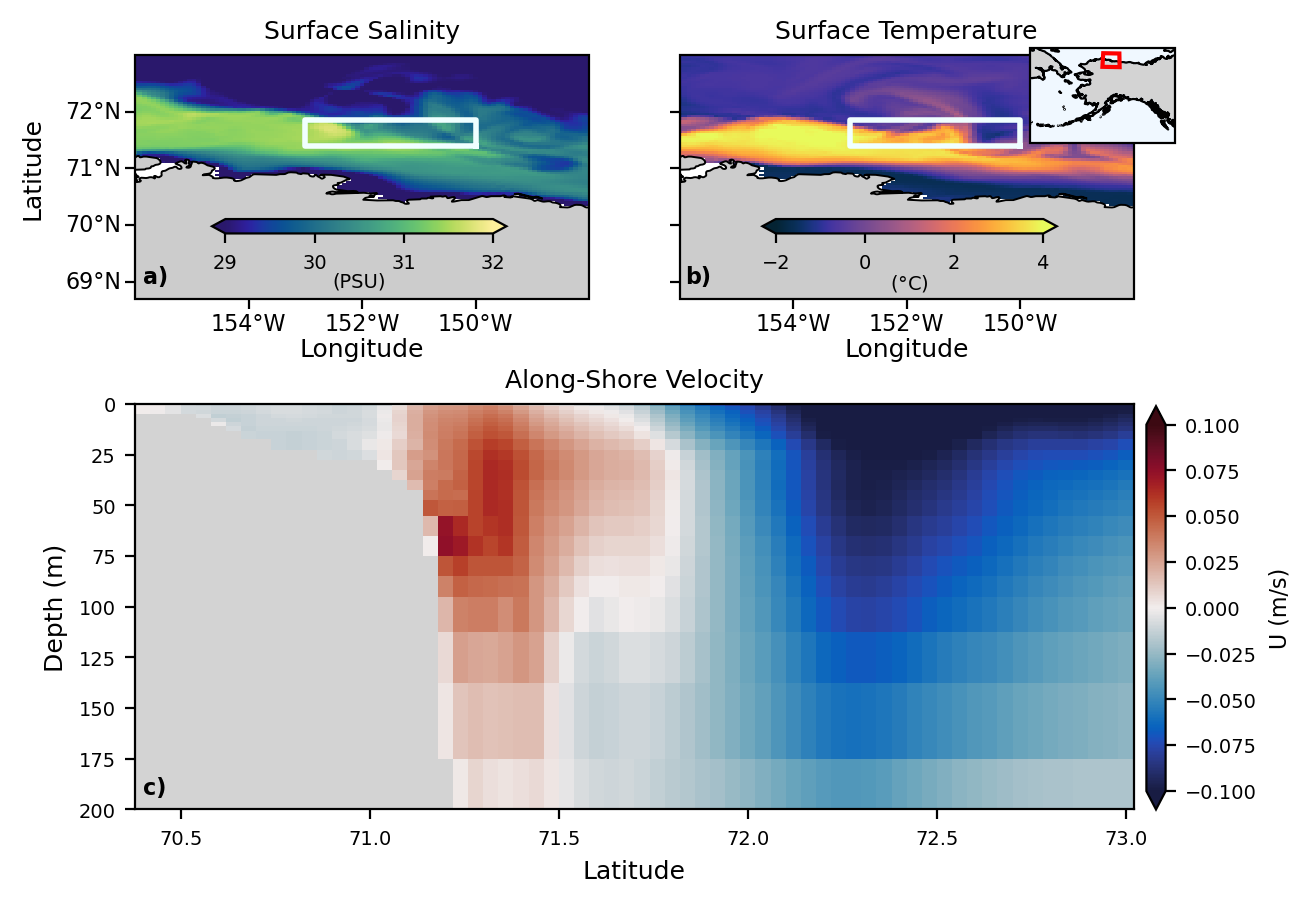

In [ ]:
# Make the study site figure with smaller longitude 
# range and snapshots for all fields (or alongshore mean
# for the jet)

# Set the min, max, and levels for u and bathymetry
lev_bathy = np.arange(10,110,10)

# Do snapshots from October 15, 2022

plt.rcParams.update({ 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 
                     'ytick.labelsize': 7, 'legend.fontsize': 7, 'figure.titlesize': 10})

fig = plt.figure(dpi=200)

gs = GridSpec(2, 2, figure=fig, left=0.10, right=0.88, top=0.95, bottom=0.08, hspace=0.06) # hspace=0.05

ax0 = fig.add_subplot(gs[0,0], projection=crs)
ax1 = fig.add_subplot(gs[0,1], projection=crs)
ax2 = fig.add_subplot(gs[1,:])
ax = [ax0, ax1, ax2]

# Plot surface salinity at 2022-10-15
m1 = hycom_salt.salinity.sel(time='2022-10-15 00:00:00', method='nearest')[0].plot(
    x='lon', y='lat',
    ax=ax[0],
    cmap=cmo.haline, transform=ccrs.PlateCarree(),
    add_colorbar=False, facecolor="gray",
    vmin=29, vmax=32
)
#ax[0].set_title('Surface Salinity @ Time: ' + '2022-10-15 00:00:00')
ax[0].set_title('Surface Salinity')
#ax[0].set_aspect(lat_rad)
# Make the colorbar
cbar_ax1 = fig.add_axes([0.16,0.68,0.23,0.015])
cbar1 = fig.colorbar(m1,extend='both', orientation='horizontal',
             pad=0.03, cax=cbar_ax1)
cbar1.set_label('(PSU)', labelpad=0.01, fontsize=7)


# Plot surface temperature at 2022-10-15
m2 = hycom_temp.water_temp.sel(time='2022-10-15 00:00:00', method='nearest')[0].plot(
    x='lon', y='lat',
    ax=ax[1],
    cmap=cmo.thermal, transform=ccrs.PlateCarree(),
    add_colorbar=False, facecolor="gray",
    vmin=-2, vmax=4
)
#ax[1].set_title('Surface Temperature @ Time: ' + '2022-10-15 00:00:00')
ax[1].set_title('Surface Temperature')
# Make the colorbar
cbar_ax2 = fig.add_axes([0.59,0.68,0.23,0.015])
cbar2 = fig.colorbar(m2, extend='both', orientation='horizontal',
             pad=0.03, cax=cbar_ax2)
cbar2.set_label('($\degree$C)', labelpad=0.01, fontsize=7)
# Add inset of Alaska to mark where we are
# --- Alaska Inset Map (Top Right of Top Panel) ---
# Define Alaska inset projection
alaska_proj = ccrs.AlbersEqualArea(central_longitude=-150, central_latitude=63)

# Create the inset directly inside the top axes (ax2[0])
# (x0, y0, width, height) are in *axes coordinates*, so 1.0 = right/top edge
#ax_inset = ax[0].inset_axes([0.747, 0.64, 0.37, 0.39], projection=alaska_proj)  # [0.68, 0.60, 0.28, 0.30] | end at 1.104 (x) and 1 (y)
ax_inset = ax[1].inset_axes([0.747, 0.64, 0.37, 0.39], projection=alaska_proj)

# ↑ adjust numbers slightly to shift or resize

# Set extent for all of Alaska
ax_inset.set_extent([-180, -129, 50, 72], crs=ccrs.PlateCarree())

# Add base map features
ax_inset.add_feature(cfeature.LAND, color='lightgray', zorder=0)
ax_inset.add_feature(cfeature.OCEAN, color='aliceblue', zorder=0)
ax_inset.coastlines(resolution='50m', linewidth=0.8)

# --- Add red rectangle showing zoomed region ---
lon_min, lon_max = -156, -148 #-137
lat_min, lat_max = 68.7, 73
rect = Rectangle((lon_min, lat_min),
                 lon_max - lon_min, lat_max - lat_min,
                 facecolor='none', edgecolor='red', linewidth=1.5,
                 transform=ccrs.PlateCarree(), zorder=5)
ax_inset.add_patch(rect)

# Optional: make the inset tidy
ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax_inset.set_frame_on(True)


# Add other details to each subplot
for r in range(2):
    # Set extent and map features
    ax[r].set_extent([-156,-148,68.7, 73],ccrs.PlateCarree()) # -137
    ax[r].add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m',
                                                facecolor='0.8'), linewidth=.7)
    ax[r].coastlines(resolution='10m', linewidth=.7)

    # Add bathymetry for the domain
    #ax[r].contour(grid.lon_rho, grid.lat_rho, grid.h, levels=lev_bathy, colors='dimgrey')

    gl = ax[r].gridlines(crs=ccrs.PlateCarree(), 
                    draw_labels=True, 
                    x_inline=False, y_inline=False, 
                    linewidth=0.33, color='k',alpha=1.0)
    # Turn off the grid lines
    gl.xlines = False
    gl.ylines = False
    # Add tick marks but not axis labels 
    ax[r].set_xticks([-154, -152, -150], crs=ccrs.PlateCarree())
    ax[r].set_yticks([69, 70, 71, 72], crs=ccrs.PlateCarree())
    ax[r].set_xticklabels([])
    ax[r].set_xlabel('')
    ax[r].set_yticklabels([])
    ax[r].set_ylabel('')

    gl.right_labels = gl.top_labels = False
    if r == 1:
        gl.left_labels=False
    gl.xlocator = ticker.FixedLocator([-156, -154, -152, -150,-148]) # [-156, -154, -152, -150,-148,-146,-144,-142, -140, -138]
    #gl.xlabel_style = {'rotation': 0, 'ha': 'center', 'fontsize':7}
    #gl.ylabel_style = {'fontsize':7}

# Pick a region to analyze 
# Box 1
box_min_lon_01 = -150
box_max_lon_01 = -153
box_min_lat_01 = 71.4
box_max_lat_01 = 71.85
# Plot Box 1
ax[0].plot([box_min_lon_01, box_max_lon_01, box_max_lon_01, box_min_lon_01, box_min_lon_01],
        [box_min_lat_01, box_min_lat_01, box_max_lat_01, box_max_lat_01, box_min_lat_01],
        color='azure', linestyle='-', linewidth=2)
ax[1].plot([box_min_lon_01, box_max_lon_01, box_max_lon_01, box_min_lon_01, box_min_lon_01],
        [box_min_lat_01, box_min_lat_01, box_max_lat_01, box_max_lat_01, box_min_lat_01],
        color='azure', linestyle='-', linewidth=2)



# Plot cross section of u in the middle of the box
# Plot a vertical transect at longitude 150
# cs3 = ax[2].pcolormesh(hycom_u.lat[80:], hycom_u.depth, hycom_u.water_u.sel(time='2022-10-15 00:00:00', lon=-151.5, method='nearest')[:,80:],
#                        vmin=-0.3, vmax=0.3, cmap=cmo.balance)
# cs3 = ax[2].pcolormesh(hycom_u.lat[60:], hycom_u.depth, hycom_u.water_u.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
#                        vmin=-0.1, vmax=0.1, cmap=cmo.balance)
cs3 = ax[2].pcolormesh(hycom_u.lat[60:], hycom_u.depth, oct_mean_u.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                       vmin=-0.1, vmax=0.1, cmap=cmo.balance)
cbar_ax3 = fig.add_axes([0.89,0.08,0.015,0.42])
fig.colorbar(cs3, extend='both', label='U (m/s)',pad=0.03, cax=cbar_ax3)
ax[2].set_title('Along-Shore Velocity')
ax[2].set_ylim(0,200)
ax[2].invert_yaxis()
ax[2].set_facecolor('lightgrey')

# Adjust subplot spacing
#plt.subplots_adjust(hspace=0.30)


# Label the axes
fig.text(0.01, 0.70, 'Latitude', rotation=90, fontsize=9)
ax[0].set_xlabel('Longitude', fontsize=9, labelpad=7)
ax[1].set_xlabel('Longitude', fontsize=9, labelpad=7)
# fig.text(0.01, 0.48, 'Latitude', rotation=90, fontsize=9)
# ax[0].set_ylabel('Latitude', fontsize=10)
#ax[1].set_ylabel('Latitude', fontsize=10)
#ax[0].set_ylabel('Latitude', fontsize=9)
ax[2].set_xlabel('Latitude', fontsize=9)
ax[2].set_ylabel('Depth (m)', fontsize=9)

# Add subplot labels
fig.text(0.106, 0.628, 'a)', color='black', weight='bold')
fig.text(0.530, 0.628, 'b)', color='black', weight='bold')
fig.text(0.106, 0.096, 'c)', color='black', weight='bold')


In [ ]:
# Plot the salinity (snapshot), temperature (snapshot), u (October mean), and v (October mean)
# for about the grid region ish to see how they look
# (Then, figure out dimensions/offshore and lateral span to make this data cover about the same 
# region as our grid (maybe make fake/approximate lat/lon for grid) to then put the data on our grid
# with the correct dimensions)

Text(0.53, 0.176, 'd)')

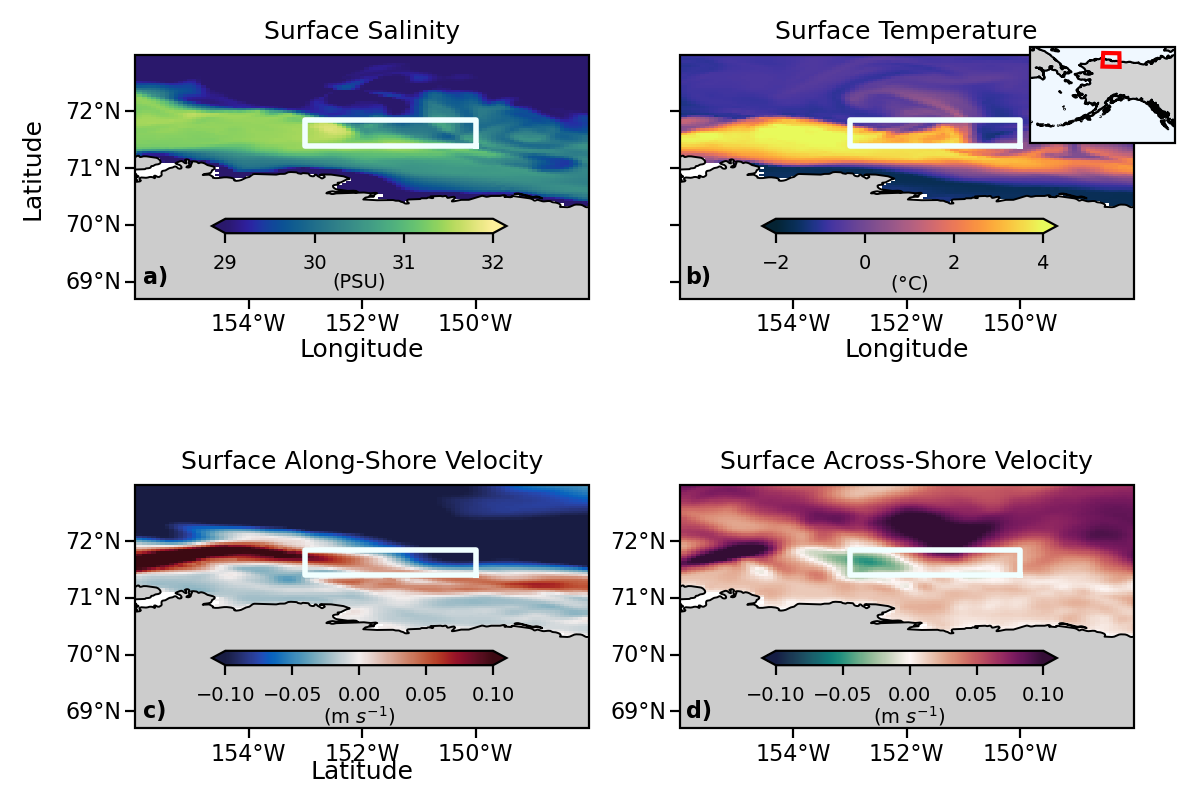

In [ ]:
# Plot the salinity (snapshot), temperature (snapshot), u (October mean), and v (October mean)
# for about the grid region ish to see how they look
# Surface plots

# Set the min, max, and levels for u and bathymetry
lev_bathy = np.arange(10,110,10)

# Do snapshots from October 15, 2022

plt.rcParams.update({ 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 
                     'ytick.labelsize': 7, 'legend.fontsize': 7, 'figure.titlesize': 10})

fig = plt.figure(dpi=200)

gs = GridSpec(2, 2, figure=fig, left=0.10, right=0.88, top=0.95, bottom=0.08, hspace=0.06) # hspace=0.05

ax0 = fig.add_subplot(gs[0,0], projection=crs)
ax1 = fig.add_subplot(gs[0,1], projection=crs)
ax2 = fig.add_subplot(gs[1,0], projection=crs)
ax3 = fig.add_subplot(gs[1,1], projection=crs)
ax = [ax0, ax1, ax2, ax3]

# Plot surface salinity at 2022-10-15
m1 = hycom_salt.salinity.sel(time='2022-10-15 00:00:00', method='nearest')[0].plot(
    x='lon', y='lat',
    ax=ax[0],
    cmap=cmo.haline, transform=ccrs.PlateCarree(),
    add_colorbar=False, facecolor="gray",
    vmin=29, vmax=32
)
#ax[0].set_title('Surface Salinity @ Time: ' + '2022-10-15 00:00:00')
ax[0].set_title('Surface Salinity')
#ax[0].set_aspect(lat_rad)
# Make the colorbar
cbar_ax1 = fig.add_axes([0.16,0.68,0.23,0.015])
cbar1 = fig.colorbar(m1,extend='both', orientation='horizontal',
             pad=0.03, cax=cbar_ax1)
cbar1.set_label('(PSU)', labelpad=0.01, fontsize=7)


# Plot surface temperature at 2022-10-15
m2 = hycom_temp.water_temp.sel(time='2022-10-15 00:00:00', method='nearest')[0].plot(
    x='lon', y='lat',
    ax=ax[1],
    cmap=cmo.thermal, transform=ccrs.PlateCarree(),
    add_colorbar=False, facecolor="gray",
    vmin=-2, vmax=4
)
#ax[1].set_title('Surface Temperature @ Time: ' + '2022-10-15 00:00:00')
ax[1].set_title('Surface Temperature')
# Make the colorbar
cbar_ax2 = fig.add_axes([0.59,0.68,0.23,0.015])
cbar2 = fig.colorbar(m2, extend='both', orientation='horizontal',
             pad=0.03, cax=cbar_ax2)
cbar2.set_label('($\degree$C)', labelpad=0.01, fontsize=7)
# Add inset of Alaska to mark where we are
# --- Alaska Inset Map (Top Right of Top Panel) ---
# Define Alaska inset projection
alaska_proj = ccrs.AlbersEqualArea(central_longitude=-150, central_latitude=63)

# Create the inset directly inside the top axes (ax2[0])
# (x0, y0, width, height) are in *axes coordinates*, so 1.0 = right/top edge
#ax_inset = ax[0].inset_axes([0.747, 0.64, 0.37, 0.39], projection=alaska_proj)  # [0.68, 0.60, 0.28, 0.30] | end at 1.104 (x) and 1 (y)
ax_inset = ax[1].inset_axes([0.747, 0.64, 0.37, 0.39], projection=alaska_proj)

# ↑ adjust numbers slightly to shift or resize

# Set extent for all of Alaska
ax_inset.set_extent([-180, -129, 50, 72], crs=ccrs.PlateCarree())

# Add base map features
ax_inset.add_feature(cfeature.LAND, color='lightgray', zorder=0)
ax_inset.add_feature(cfeature.OCEAN, color='aliceblue', zorder=0)
ax_inset.coastlines(resolution='50m', linewidth=0.8)

# --- Add red rectangle showing zoomed region ---
lon_min, lon_max = -156, -148 #-137
lat_min, lat_max = 68.7, 73
rect = Rectangle((lon_min, lat_min),
                 lon_max - lon_min, lat_max - lat_min,
                 facecolor='none', edgecolor='red', linewidth=1.5,
                 transform=ccrs.PlateCarree(), zorder=5)
ax_inset.add_patch(rect)

# Optional: make the inset tidy
ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax_inset.set_frame_on(True)


# Plot October mean u
m3 = oct_mean_u[0].plot(
    x='lon', y='lat',
    ax=ax[2],
    cmap=cmo.balance, transform=ccrs.PlateCarree(),
    add_colorbar=False, facecolor="gray",
    vmin=-0.1, vmax=0.1
)
ax[2].set_title('Surface Along-Shore Velocity')
# Make the colorbar
cbar_ax3 = fig.add_axes([0.16,0.23,0.23,0.015])
cbar3 = fig.colorbar(m3,extend='both', orientation='horizontal',
             pad=0.03, cax=cbar_ax3)
cbar3.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)


# Plot October mean v
m4 = oct_mean_v[0].plot(
    x='lon', y='lat',
    ax=ax[3],
    cmap=cmo.curl, transform=ccrs.PlateCarree(),
    add_colorbar=False, facecolor="gray",
    vmin=-0.1, vmax=0.1
)
ax[3].set_title('Surface Across-Shore Velocity')
# Make the colorbar
cbar_ax4 = fig.add_axes([0.59,0.23,0.23,0.015])
cbar4 = fig.colorbar(m4,extend='both', orientation='horizontal',
             pad=0.03, cax=cbar_ax4)
cbar4.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)


# Add other details to each subplot
for r in range(4):
    # Set extent and map features
    ax[r].set_extent([-156,-148,68.7, 73],ccrs.PlateCarree()) # -137
    ax[r].add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m',
                                                facecolor='0.8'), linewidth=.7)
    ax[r].coastlines(resolution='10m', linewidth=.7)

    # Add bathymetry for the domain
    #ax[r].contour(grid.lon_rho, grid.lat_rho, grid.h, levels=lev_bathy, colors='dimgrey')

    gl = ax[r].gridlines(crs=ccrs.PlateCarree(), 
                    draw_labels=True, 
                    x_inline=False, y_inline=False, 
                    linewidth=0.33, color='k',alpha=1.0)
    # Turn off the grid lines
    gl.xlines = False
    gl.ylines = False
    # Add tick marks but not axis labels 
    ax[r].set_xticks([-154, -152, -150], crs=ccrs.PlateCarree())
    ax[r].set_yticks([69, 70, 71, 72], crs=ccrs.PlateCarree())
    ax[r].set_xticklabels([])
    ax[r].set_xlabel('')
    ax[r].set_yticklabels([])
    ax[r].set_ylabel('')

    gl.right_labels = gl.top_labels = False
    if r == 1:
        gl.left_labels=False
    gl.xlocator = ticker.FixedLocator([-156, -154, -152, -150,-148]) # [-156, -154, -152, -150,-148,-146,-144,-142, -140, -138]
    #gl.xlabel_style = {'rotation': 0, 'ha': 'center', 'fontsize':7}
    #gl.ylabel_style = {'fontsize':7}

    # Pick a region to analyze 
    # Box 1
    box_min_lon_01 = -150
    box_max_lon_01 = -153
    box_min_lat_01 = 71.4
    box_max_lat_01 = 71.85
    # Plot Box 1
    ax[r].plot([box_min_lon_01, box_max_lon_01, box_max_lon_01, box_min_lon_01, box_min_lon_01],
            [box_min_lat_01, box_min_lat_01, box_max_lat_01, box_max_lat_01, box_min_lat_01],
            color='azure', linestyle='-', linewidth=2)


# Adjust subplot spacing
#plt.subplots_adjust(hspace=0.00001)


# Label the axes
fig.text(0.01, 0.70, 'Latitude', rotation=90, fontsize=9)
ax[0].set_xlabel('Longitude', fontsize=9, labelpad=7)
ax[1].set_xlabel('Longitude', fontsize=9, labelpad=7)
# fig.text(0.01, 0.48, 'Latitude', rotation=90, fontsize=9)
# ax[0].set_ylabel('Latitude', fontsize=10)
#ax[1].set_ylabel('Latitude', fontsize=10)
#ax[0].set_ylabel('Latitude', fontsize=9)
ax[2].set_xlabel('Latitude', fontsize=9)
#ax[2].set_ylabel('Depth (m)', fontsize=9)

# Add subplot labels
fig.text(0.106, 0.628, 'a)', color='black', weight='bold')
fig.text(0.530, 0.628, 'b)', color='black', weight='bold')
fig.text(0.106, 0.176, 'c)', color='black', weight='bold')
fig.text(0.530, 0.176, 'd)', color='black', weight='bold')


Text(0.106, 0.096, 'd)')

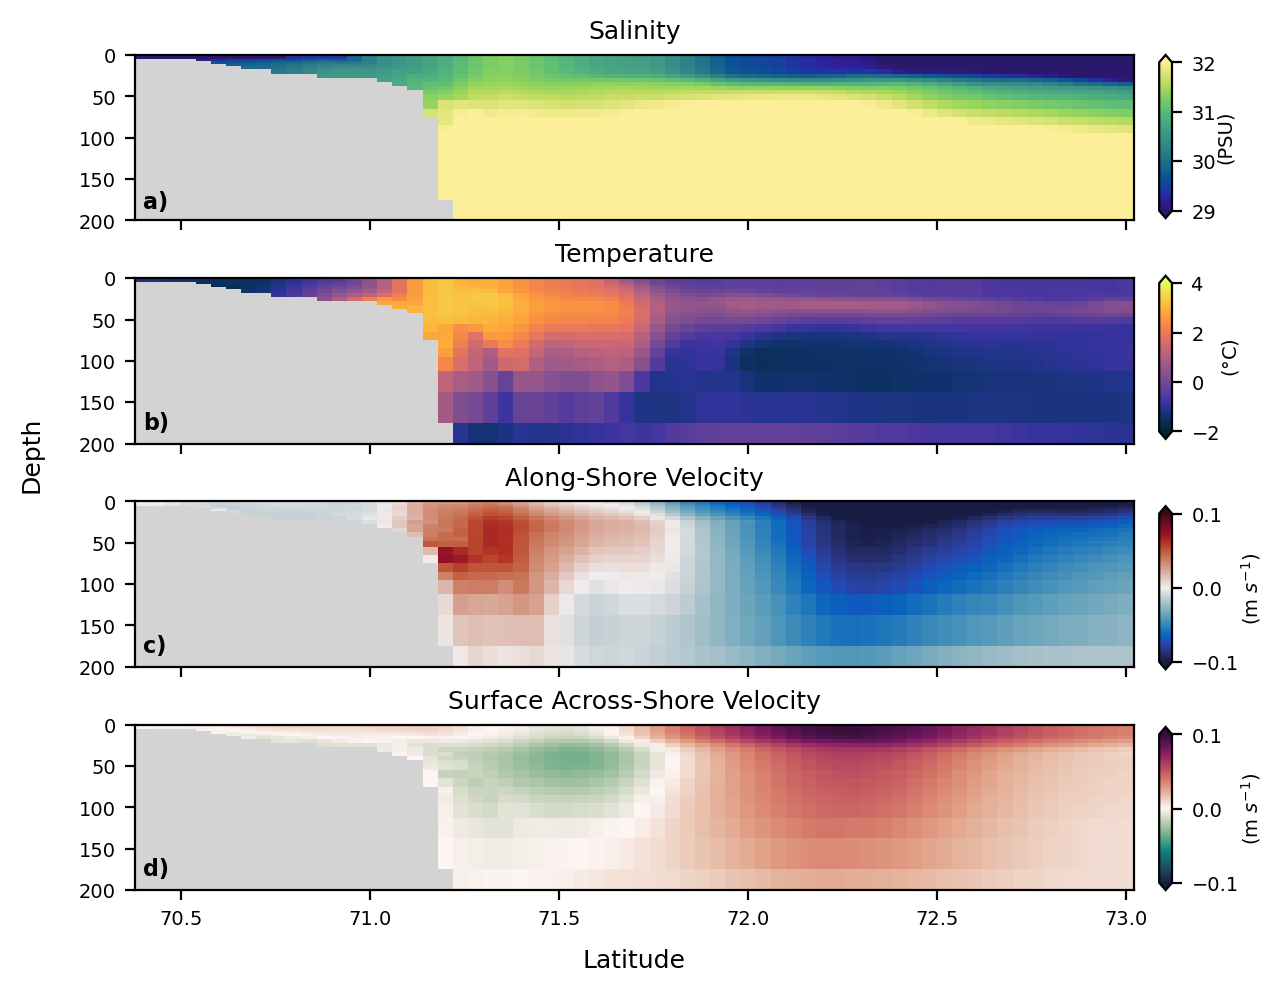

In [ ]:
# Same as above but vertical along-shore means

# Plot the salinity (snapshot), temperature (snapshot), u (October mean), and v (October mean)
# for about the grid region ish to see how they look

# Set the min, max, and levels for u and bathymetry
lev_bathy = np.arange(10,110,10)

# Do snapshots from October 15, 2022

plt.rcParams.update({ 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 
                     'ytick.labelsize': 7, 'legend.fontsize': 7, 'figure.titlesize': 10})

fig = plt.figure(dpi=200)

gs = GridSpec(4, 1, figure=fig, left=0.10, right=0.88, top=0.95, bottom=0.08, hspace=0.35) # hspace=0.05

ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])
ax2 = fig.add_subplot(gs[2])
ax3 = fig.add_subplot(gs[3])
ax = [ax0, ax1, ax2, ax3]


# Plot salinity at 2022-10-15
m1 = ax[0].pcolormesh(hycom_salt.lat[60:], hycom_salt.depth, 
                      hycom_salt.salinity.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=29, vmax=32, cmap=cmo.haline)
#ax[0].set_title('Surface Salinity @ Time: ' + '2022-10-15 00:00:00')
ax[0].set_title('Salinity')
#ax[0].set_aspect(lat_rad)
# Make the colorbar
cbar_ax1 = fig.add_axes([0.90,0.78,0.01,0.17])
cbar1 = fig.colorbar(m1,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax1)
cbar1.set_label('(PSU)', labelpad=0.01, fontsize=7)
ax[0].set_ylim(0,200)
ax[0].invert_yaxis()
ax[0].set_facecolor('lightgrey')
ax[0].tick_params(labelbottom=False)


# Plot surface temperature at 2022-10-15
m2 = ax[1].pcolormesh(hycom_temp.lat[60:], hycom_temp.depth, 
                      hycom_temp.water_temp.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-2, vmax=4, cmap=cmo.thermal)
#ax[1].set_title('Surface Temperature @ Time: ' + '2022-10-15 00:00:00')
ax[1].set_title('Temperature')
# Make the colorbar
cbar_ax2 = fig.add_axes([0.90,0.55,0.01,0.17])
cbar2 = fig.colorbar(m2, extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax2)
cbar2.set_label('($\degree$C)', labelpad=0.01, fontsize=7)
ax[1].set_ylim(0,200)
ax[1].invert_yaxis()
ax[1].set_facecolor('lightgrey')
ax[1].tick_params(labelbottom=False)

# Plot October mean u
m3 = ax[2].pcolormesh(hycom_u.lat[60:], hycom_u.depth, 
                      oct_mean_u.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.1, vmax=0.1, cmap=cmo.balance)
ax[2].set_title('Along-Shore Velocity')
# Make the colorbar
cbar_ax3 = fig.add_axes([0.90,0.31,0.01,0.17])
cbar3 = fig.colorbar(m3,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax3)
cbar3.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[2].set_ylim(0,200)
ax[2].invert_yaxis()
ax[2].set_facecolor('lightgrey')
ax[2].tick_params(labelbottom=False)

# Plot October mean v
m4 = ax[3].pcolormesh(hycom_v.lat[60:], hycom_v.depth, 
                      oct_mean_v.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.1, vmax=0.1, cmap=cmo.curl)
ax[3].set_title('Surface Across-Shore Velocity')
# Make the colorbar
cbar_ax4 = fig.add_axes([0.90,0.08,0.01,0.17])
cbar4 = fig.colorbar(m4,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax4)
cbar4.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[3].set_ylim(0,200)
ax[3].invert_yaxis()
ax[3].set_facecolor('lightgrey')


# Label the axes
fig.text(0.01, 0.50, 'Depth', rotation=90, fontsize=9)
ax[3].set_xlabel('Latitude', fontsize=9, labelpad=7)


# Add subplot labels
fig.text(0.106, 0.790, 'a)', color='black', weight='bold')
fig.text(0.106, 0.560, 'b)', color='black', weight='bold')
fig.text(0.106, 0.328, 'c)', color='black', weight='bold')
fig.text(0.106, 0.096, 'd)', color='black', weight='bold')


Text(0.106, 0.096, 'd)')

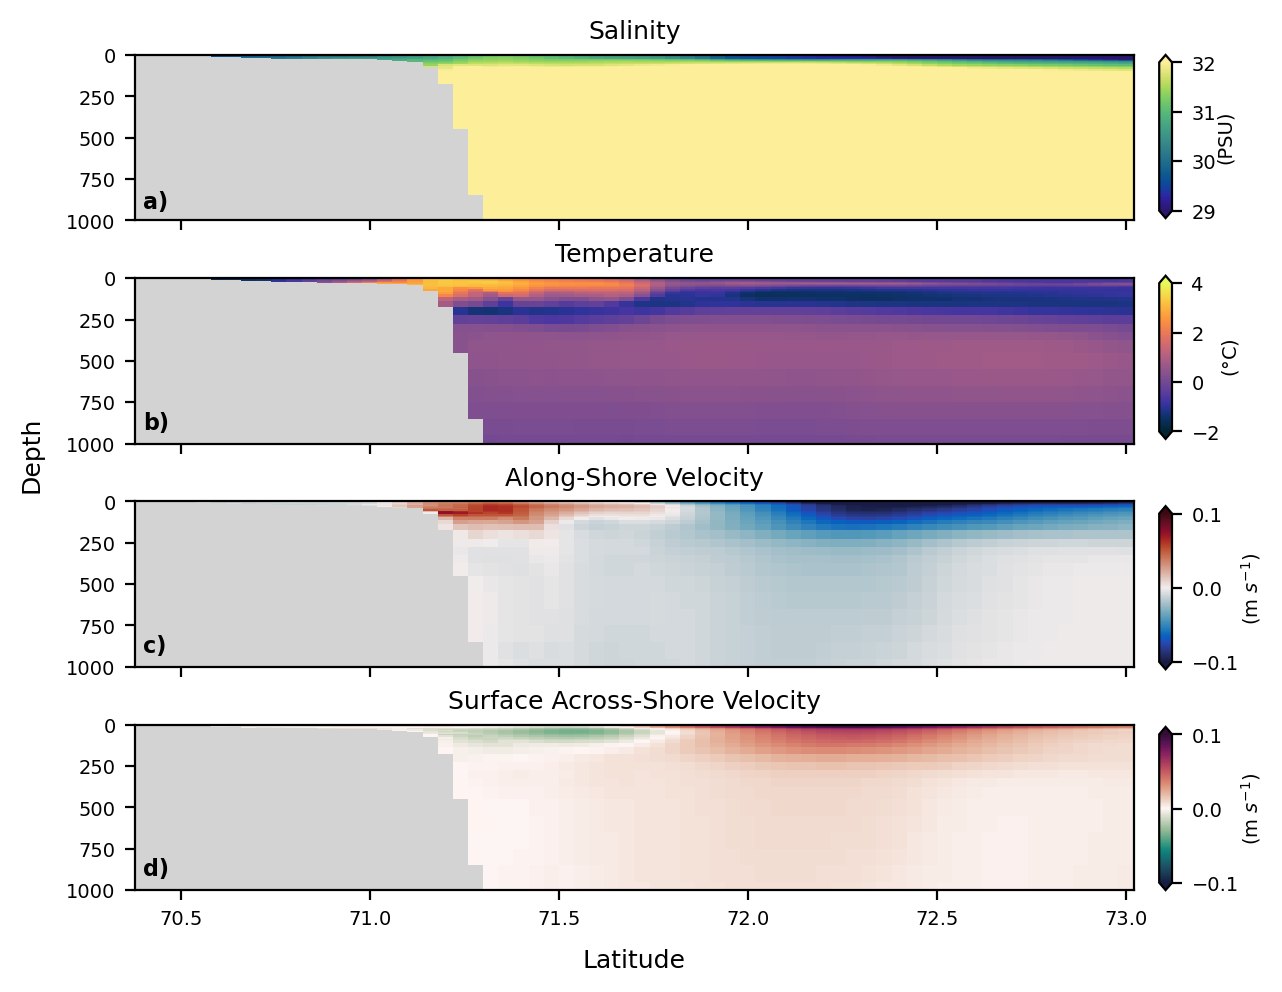

In [78]:
# Plot again but looking all the way to deeper depths 

# Plot the salinity (snapshot), temperature (snapshot), u (October mean), and v (October mean)
# for about the grid region ish to see how they look

# Set the min, max, and levels for u and bathymetry
lev_bathy = np.arange(10,110,10)

# Do snapshots from October 15, 2022

plt.rcParams.update({ 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 
                     'ytick.labelsize': 7, 'legend.fontsize': 7, 'figure.titlesize': 10})

fig = plt.figure(dpi=200)

gs = GridSpec(4, 1, figure=fig, left=0.10, right=0.88, top=0.95, bottom=0.08, hspace=0.35) # hspace=0.05

ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])
ax2 = fig.add_subplot(gs[2])
ax3 = fig.add_subplot(gs[3])
ax = [ax0, ax1, ax2, ax3]


# Plot salinity at 2022-10-15
m1 = ax[0].pcolormesh(hycom_salt.lat[60:], hycom_salt.depth, 
                      hycom_salt.salinity.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=29, vmax=32, cmap=cmo.haline)
#ax[0].set_title('Surface Salinity @ Time: ' + '2022-10-15 00:00:00')
ax[0].set_title('Salinity')
#ax[0].set_aspect(lat_rad)
# Make the colorbar
cbar_ax1 = fig.add_axes([0.90,0.78,0.01,0.17])
cbar1 = fig.colorbar(m1,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax1)
cbar1.set_label('(PSU)', labelpad=0.01, fontsize=7)
ax[0].set_ylim(0,1000)
ax[0].invert_yaxis()
ax[0].set_facecolor('lightgrey')
ax[0].tick_params(labelbottom=False)


# Plot surface temperature at 2022-10-15
m2 = ax[1].pcolormesh(hycom_temp.lat[60:], hycom_temp.depth, 
                      hycom_temp.water_temp.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-2, vmax=4, cmap=cmo.thermal)
#ax[1].set_title('Surface Temperature @ Time: ' + '2022-10-15 00:00:00')
ax[1].set_title('Temperature')
# Make the colorbar
cbar_ax2 = fig.add_axes([0.90,0.55,0.01,0.17])
cbar2 = fig.colorbar(m2, extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax2)
cbar2.set_label('($\degree$C)', labelpad=0.01, fontsize=7)
ax[1].set_ylim(0,1000)
ax[1].invert_yaxis()
ax[1].set_facecolor('lightgrey')
ax[1].tick_params(labelbottom=False)

# Plot October mean u
m3 = ax[2].pcolormesh(hycom_u.lat[60:], hycom_u.depth, 
                      oct_mean_u.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.1, vmax=0.1, cmap=cmo.balance)
ax[2].set_title('Along-Shore Velocity')
# Make the colorbar
cbar_ax3 = fig.add_axes([0.90,0.31,0.01,0.17])
cbar3 = fig.colorbar(m3,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax3)
cbar3.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[2].set_ylim(0,1000)
ax[2].invert_yaxis()
ax[2].set_facecolor('lightgrey')
ax[2].tick_params(labelbottom=False)

# Plot October mean v
m4 = ax[3].pcolormesh(hycom_v.lat[60:], hycom_v.depth, 
                      oct_mean_v.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.1, vmax=0.1, cmap=cmo.curl)
ax[3].set_title('Surface Across-Shore Velocity')
# Make the colorbar
cbar_ax4 = fig.add_axes([0.90,0.08,0.01,0.17])
cbar4 = fig.colorbar(m4,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax4)
cbar4.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[3].set_ylim(0,1000)
ax[3].invert_yaxis()
ax[3].set_facecolor('lightgrey')


# Label the axes
fig.text(0.01, 0.50, 'Depth', rotation=90, fontsize=9)
ax[3].set_xlabel('Latitude', fontsize=9, labelpad=7)


# Add subplot labels
fig.text(0.106, 0.790, 'a)', color='black', weight='bold')
fig.text(0.106, 0.560, 'b)', color='black', weight='bold')
fig.text(0.106, 0.328, 'c)', color='black', weight='bold')
fig.text(0.106, 0.096, 'd)', color='black', weight='bold')

Text(0.106, 0.096, 'd)')

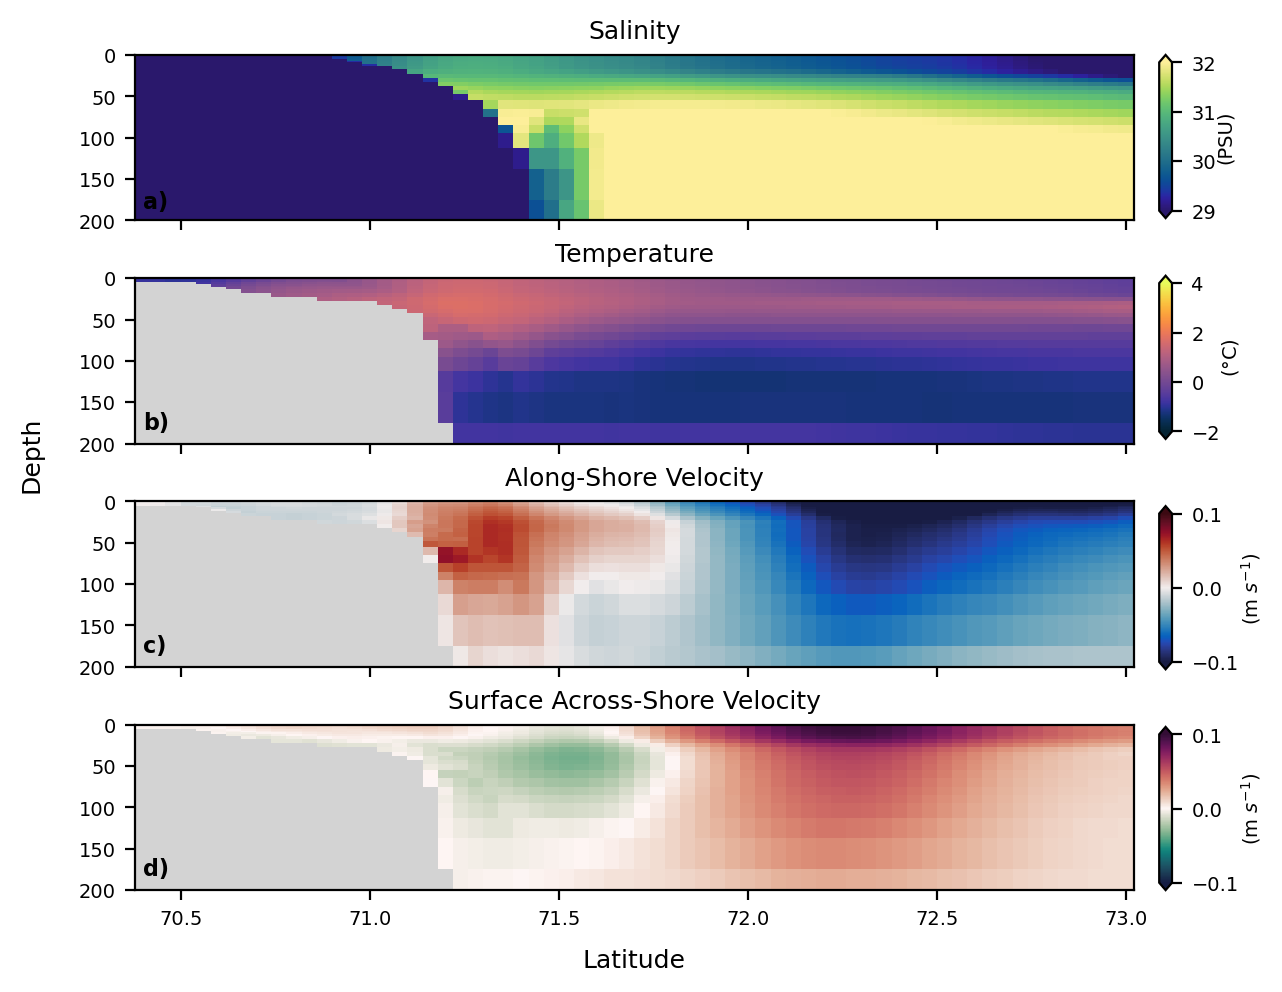

In [80]:
# Plot again but with October means for salt and temp, too, since 
# the other plots use that for u and v 
# Same as above but vertical along-shore means

# Plot the salinity (snapshot), temperature (snapshot), u (October mean), and v (October mean)
# for about the grid region ish to see how they look

# Set the min, max, and levels for u and bathymetry
lev_bathy = np.arange(10,110,10)

# Do snapshots from October 15, 2022

plt.rcParams.update({ 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 
                     'ytick.labelsize': 7, 'legend.fontsize': 7, 'figure.titlesize': 10})

fig = plt.figure(dpi=200)

gs = GridSpec(4, 1, figure=fig, left=0.10, right=0.88, top=0.95, bottom=0.08, hspace=0.35) # hspace=0.05

ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])
ax2 = fig.add_subplot(gs[2])
ax3 = fig.add_subplot(gs[3])
ax = [ax0, ax1, ax2, ax3]


# Plot salinity at 2022-10-15
m1 = ax[0].pcolormesh(hycom_salt.lat[60:], hycom_salt.depth, 
                      oct_mean_salt.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=29, vmax=32, cmap=cmo.haline)
#ax[0].set_title('Surface Salinity @ Time: ' + '2022-10-15 00:00:00')
ax[0].set_title('Salinity')
#ax[0].set_aspect(lat_rad)
# Make the colorbar
cbar_ax1 = fig.add_axes([0.90,0.78,0.01,0.17])
cbar1 = fig.colorbar(m1,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax1)
cbar1.set_label('(PSU)', labelpad=0.01, fontsize=7)
ax[0].set_ylim(0,200)
ax[0].invert_yaxis()
ax[0].set_facecolor('lightgrey')
ax[0].tick_params(labelbottom=False)


# Plot surface temperature at 2022-10-15
m2 = ax[1].pcolormesh(hycom_temp.lat[60:], hycom_temp.depth, 
                      oct_mean_temp.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-2, vmax=4, cmap=cmo.thermal)
#ax[1].set_title('Surface Temperature @ Time: ' + '2022-10-15 00:00:00')
ax[1].set_title('Temperature')
# Make the colorbar
cbar_ax2 = fig.add_axes([0.90,0.55,0.01,0.17])
cbar2 = fig.colorbar(m2, extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax2)
cbar2.set_label('($\degree$C)', labelpad=0.01, fontsize=7)
ax[1].set_ylim(0,200)
ax[1].invert_yaxis()
ax[1].set_facecolor('lightgrey')
ax[1].tick_params(labelbottom=False)

# Plot October mean u
m3 = ax[2].pcolormesh(hycom_u.lat[60:], hycom_u.depth, 
                      oct_mean_u.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.1, vmax=0.1, cmap=cmo.balance)
ax[2].set_title('Along-Shore Velocity')
# Make the colorbar
cbar_ax3 = fig.add_axes([0.90,0.31,0.01,0.17])
cbar3 = fig.colorbar(m3,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax3)
cbar3.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[2].set_ylim(0,200)
ax[2].invert_yaxis()
ax[2].set_facecolor('lightgrey')
ax[2].tick_params(labelbottom=False)

# Plot October mean v
m4 = ax[3].pcolormesh(hycom_v.lat[60:], hycom_v.depth, 
                      oct_mean_v.sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.1, vmax=0.1, cmap=cmo.curl)
ax[3].set_title('Surface Across-Shore Velocity')
# Make the colorbar
cbar_ax4 = fig.add_axes([0.90,0.08,0.01,0.17])
cbar4 = fig.colorbar(m4,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax4)
cbar4.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[3].set_ylim(0,200)
ax[3].invert_yaxis()
ax[3].set_facecolor('lightgrey')


# Label the axes
fig.text(0.01, 0.50, 'Depth', rotation=90, fontsize=9)
ax[3].set_xlabel('Latitude', fontsize=9, labelpad=7)


# Add subplot labels
fig.text(0.106, 0.790, 'a)', color='black', weight='bold')
fig.text(0.106, 0.560, 'b)', color='black', weight='bold')
fig.text(0.106, 0.328, 'c)', color='black', weight='bold')
fig.text(0.106, 0.096, 'd)', color='black', weight='bold')

Nope, don't use October means for salinity and temperature...I think that smooths some spatial variability that we want

Text(0.106, 0.096, 'd)')

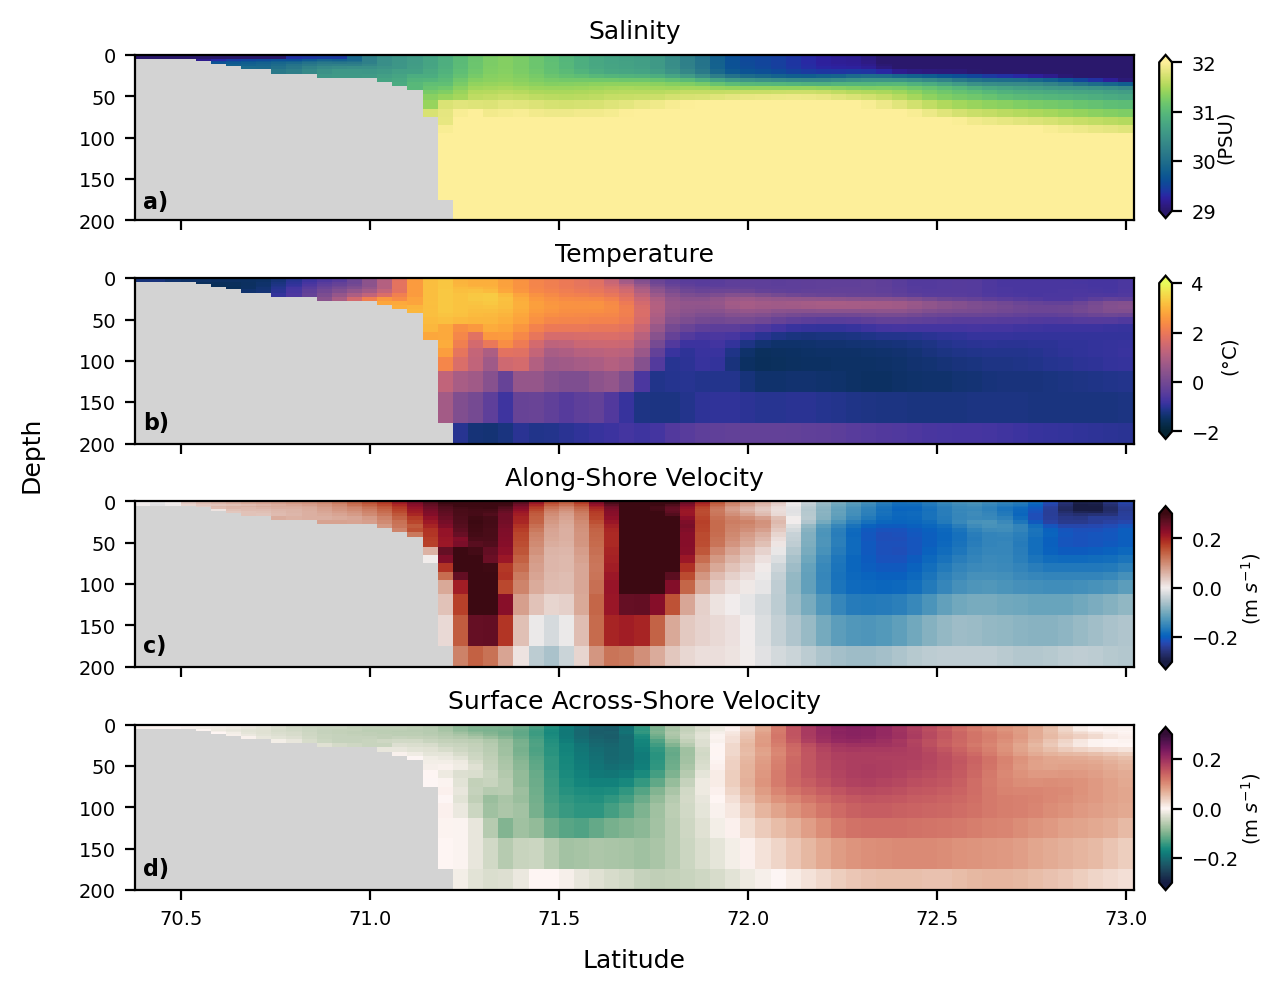

In [82]:
# Plot again but snapshots for u and v instead of October means

# Same as above but vertical along-shore means

# Plot the salinity (snapshot), temperature (snapshot), u (October mean), and v (October mean)
# for about the grid region ish to see how they look

# Set the min, max, and levels for u and bathymetry
lev_bathy = np.arange(10,110,10)

# Do snapshots from October 15, 2022

plt.rcParams.update({ 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 
                     'ytick.labelsize': 7, 'legend.fontsize': 7, 'figure.titlesize': 10})

fig = plt.figure(dpi=200)

gs = GridSpec(4, 1, figure=fig, left=0.10, right=0.88, top=0.95, bottom=0.08, hspace=0.35) # hspace=0.05

ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])
ax2 = fig.add_subplot(gs[2])
ax3 = fig.add_subplot(gs[3])
ax = [ax0, ax1, ax2, ax3]


# Plot salinity at 2022-10-15
m1 = ax[0].pcolormesh(hycom_salt.lat[60:], hycom_salt.depth, 
                      hycom_salt.salinity.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=29, vmax=32, cmap=cmo.haline)
#ax[0].set_title('Surface Salinity @ Time: ' + '2022-10-15 00:00:00')
ax[0].set_title('Salinity')
#ax[0].set_aspect(lat_rad)
# Make the colorbar
cbar_ax1 = fig.add_axes([0.90,0.78,0.01,0.17])
cbar1 = fig.colorbar(m1,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax1)
cbar1.set_label('(PSU)', labelpad=0.01, fontsize=7)
ax[0].set_ylim(0,200)
ax[0].invert_yaxis()
ax[0].set_facecolor('lightgrey')
ax[0].tick_params(labelbottom=False)


# Plot surface temperature at 2022-10-15
m2 = ax[1].pcolormesh(hycom_temp.lat[60:], hycom_temp.depth, 
                      hycom_temp.water_temp.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-2, vmax=4, cmap=cmo.thermal)
#ax[1].set_title('Surface Temperature @ Time: ' + '2022-10-15 00:00:00')
ax[1].set_title('Temperature')
# Make the colorbar
cbar_ax2 = fig.add_axes([0.90,0.55,0.01,0.17])
cbar2 = fig.colorbar(m2, extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax2)
cbar2.set_label('($\degree$C)', labelpad=0.01, fontsize=7)
ax[1].set_ylim(0,200)
ax[1].invert_yaxis()
ax[1].set_facecolor('lightgrey')
ax[1].tick_params(labelbottom=False)

# Plot October mean u
m3 = ax[2].pcolormesh(hycom_u.lat[60:], hycom_u.depth, 
                      hycom_u.water_u.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.3, vmax=0.3, cmap=cmo.balance)
ax[2].set_title('Along-Shore Velocity')
# Make the colorbar
cbar_ax3 = fig.add_axes([0.90,0.31,0.01,0.17])
cbar3 = fig.colorbar(m3,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax3)
cbar3.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[2].set_ylim(0,200)
ax[2].invert_yaxis()
ax[2].set_facecolor('lightgrey')
ax[2].tick_params(labelbottom=False)

# Plot October mean v
m4 = ax[3].pcolormesh(hycom_v.lat[60:], hycom_v.depth, 
                      hycom_v.water_v.sel(time='2022-10-15 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.3, vmax=0.3, cmap=cmo.curl)
ax[3].set_title('Surface Across-Shore Velocity')
# Make the colorbar
cbar_ax4 = fig.add_axes([0.90,0.08,0.01,0.17])
cbar4 = fig.colorbar(m4,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax4)
cbar4.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[3].set_ylim(0,200)
ax[3].invert_yaxis()
ax[3].set_facecolor('lightgrey')


# Label the axes
fig.text(0.01, 0.50, 'Depth', rotation=90, fontsize=9)
ax[3].set_xlabel('Latitude', fontsize=9, labelpad=7)


# Add subplot labels
fig.text(0.106, 0.790, 'a)', color='black', weight='bold')
fig.text(0.106, 0.560, 'b)', color='black', weight='bold')
fig.text(0.106, 0.328, 'c)', color='black', weight='bold')
fig.text(0.106, 0.096, 'd)', color='black', weight='bold')

Snapshots for u and v having faster velocities which could be good...but the along-shore mean has two locations for the jet in u which is a little weird...  
Is there a time when the snapshot along-shore mean of u does not have two jets?

Text(0.106, 0.096, 'd)')

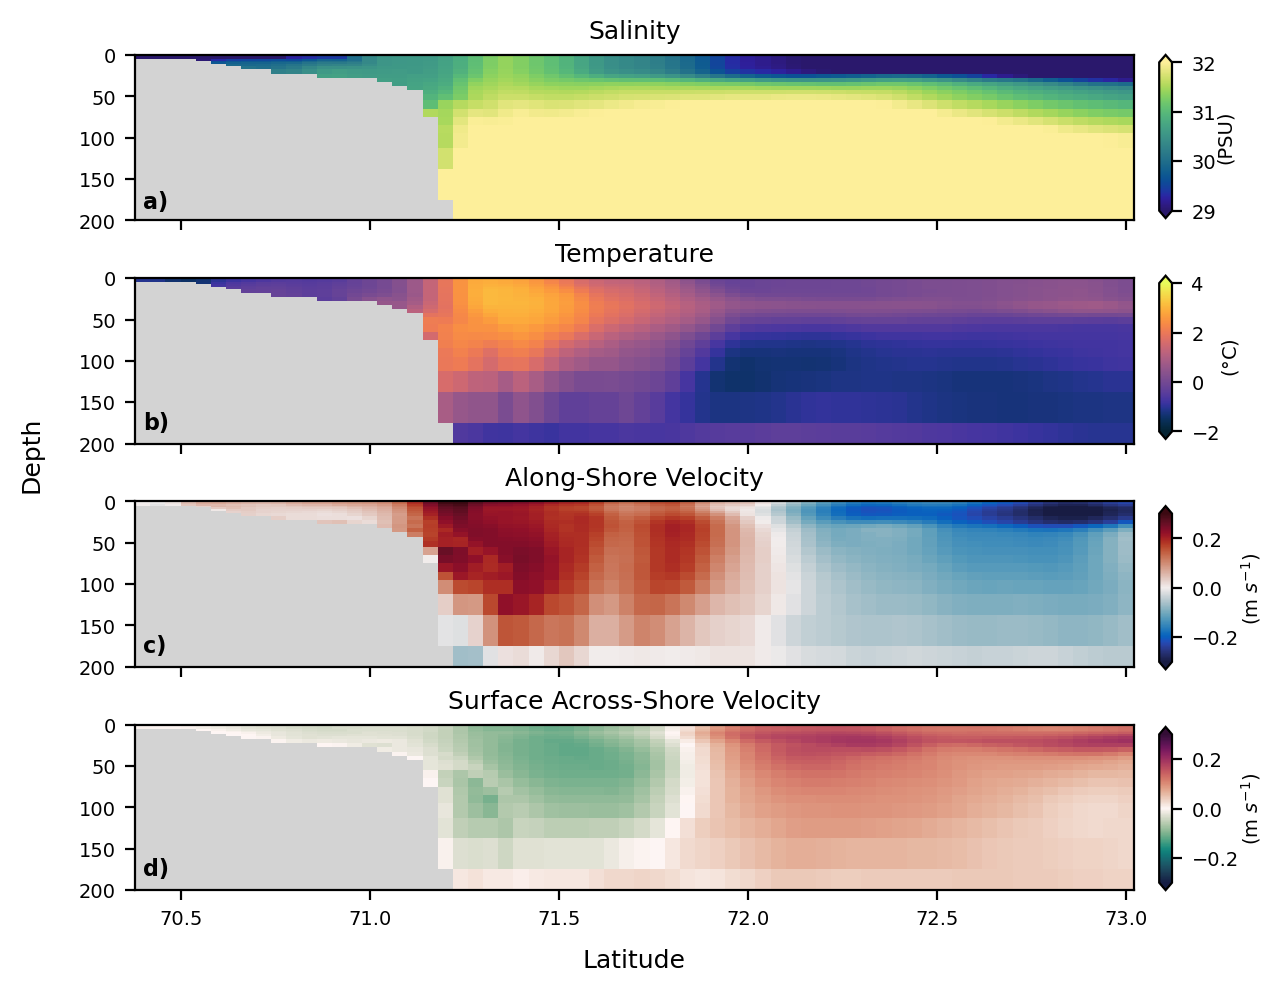

In [ ]:
# Look for time with u with one jet

# Set the min, max, and levels for u and bathymetry
lev_bathy = np.arange(10,110,10)

plt.rcParams.update({ 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 
                     'ytick.labelsize': 7, 'legend.fontsize': 7, 'figure.titlesize': 10})

fig = plt.figure(dpi=200)

gs = GridSpec(4, 1, figure=fig, left=0.10, right=0.88, top=0.95, bottom=0.08, hspace=0.35) # hspace=0.05

ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])
ax2 = fig.add_subplot(gs[2])
ax3 = fig.add_subplot(gs[3])
ax = [ax0, ax1, ax2, ax3]


# Plot salinity at 2022-10-15
m1 = ax[0].pcolormesh(hycom_salt.lat[60:], hycom_salt.depth, 
                      hycom_salt.salinity.sel(time='2022-10-10 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=29, vmax=32, cmap=cmo.haline)
#ax[0].set_title('Surface Salinity @ Time: ' + '2022-10-15 00:00:00')
ax[0].set_title('Salinity')
#ax[0].set_aspect(lat_rad)
# Make the colorbar
cbar_ax1 = fig.add_axes([0.90,0.78,0.01,0.17])
cbar1 = fig.colorbar(m1,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax1)
cbar1.set_label('(PSU)', labelpad=0.01, fontsize=7)
ax[0].set_ylim(0,200)
ax[0].invert_yaxis()
ax[0].set_facecolor('lightgrey')
ax[0].tick_params(labelbottom=False)


# Plot surface temperature at 2022-10-15
m2 = ax[1].pcolormesh(hycom_temp.lat[60:], hycom_temp.depth, 
                      hycom_temp.water_temp.sel(time='2022-10-10 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-2, vmax=4, cmap=cmo.thermal)
#ax[1].set_title('Surface Temperature @ Time: ' + '2022-10-15 00:00:00')
ax[1].set_title('Temperature')
# Make the colorbar
cbar_ax2 = fig.add_axes([0.90,0.55,0.01,0.17])
cbar2 = fig.colorbar(m2, extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax2)
cbar2.set_label('($\degree$C)', labelpad=0.01, fontsize=7)
ax[1].set_ylim(0,200)
ax[1].invert_yaxis()
ax[1].set_facecolor('lightgrey')
ax[1].tick_params(labelbottom=False)

# Plot October mean u
m3 = ax[2].pcolormesh(hycom_u.lat[60:], hycom_u.depth, 
                      hycom_u.water_u.sel(time='2022-10-10 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.3, vmax=0.3, cmap=cmo.balance)
ax[2].set_title('Along-Shore Velocity')
# Make the colorbar
cbar_ax3 = fig.add_axes([0.90,0.31,0.01,0.17])
cbar3 = fig.colorbar(m3,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax3)
cbar3.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[2].set_ylim(0,200)
ax[2].invert_yaxis()
ax[2].set_facecolor('lightgrey')
ax[2].tick_params(labelbottom=False)

# Plot October mean v
m4 = ax[3].pcolormesh(hycom_v.lat[60:], hycom_v.depth, 
                      hycom_v.water_v.sel(time='2022-10-10 00:00:00', method='nearest').sel(lon=lon_slice).mean(dim='lon')[:,60:],
                      vmin=-0.3, vmax=0.3, cmap=cmo.curl)
ax[3].set_title('Surface Across-Shore Velocity')
# Make the colorbar
cbar_ax4 = fig.add_axes([0.90,0.08,0.01,0.17])
cbar4 = fig.colorbar(m4,extend='both', orientation='vertical',
             pad=0.03, cax=cbar_ax4)
cbar4.set_label('(m $s^{-1}$)', labelpad=0.01, fontsize=7)
ax[3].set_ylim(0,200)
ax[3].invert_yaxis()
ax[3].set_facecolor('lightgrey')


# Label the axes
fig.text(0.01, 0.50, 'Depth', rotation=90, fontsize=9)
ax[3].set_xlabel('Latitude', fontsize=9, labelpad=7)


# Add subplot labels
fig.text(0.106, 0.790, 'a)', color='black', weight='bold')
fig.text(0.106, 0.560, 'b)', color='black', weight='bold')
fig.text(0.106, 0.328, 'c)', color='black', weight='bold')
fig.text(0.106, 0.096, 'd)', color='black', weight='bold')

### Adapt for the Grid

In [ ]:
# Now lets use these HYCOM data conditions to form initial conditions
# for our model 
# First, find the spatial dimensions of our grid


<xarray.Dataset> Size: 20GB
Dimensions:          (lon: 238, lat: 126, depth: 40, time: 2075)
Coordinates:
  * lon              (lon) float64 2kB 204.0 204.1 204.2 ... 222.8 222.9 223.0
  * lat              (lat) float64 1kB 68.0 68.04 68.08 ... 72.92 72.96 73.0
  * depth            (depth) float64 320B 0.0 2.0 4.0 6.0 ... 3e+03 4e+03 5e+03
  * time             (time) datetime64[ns] 17kB 2019-01-01T09:00:00 ... 2024-...
Data variables:
    salinity_bottom  (time, lat, lon) float64 498MB ...
    salinity         (time, depth, lat, lon) float64 20GB ...
Attributes: (12/17)
    CDI:                       Climate Data Interface version 2.5.0 (https://...
    Conventions:               CF-1.6 NAVO_netcdf_v1.1
    source:                    HYCOM archive file
    institution:               Fleet Numerical Meteorology and Oceanography C...
    classification_level:      UNCLASSIFIED
    distribution_statement:    Approved for public release. Distribution unli...
    ...                        ...
    History:                   Translated to CF-1.0 Conventions by Netcdf-Jav...
    geospatial_lat_min:        68.0
    geospatial_lat_max:        73.0
    geospatial_lon_min:        -156.0
    geospatial_lon_max:        -137.03997802734375
    CDO:                       Climate Data Operators version 2.5.0 (https://...